# ChurnIQ — Customer Churn Intelligence & Retention Prediction System

## Business problem

A telecom company is experiencing customer churn and wants to identify customers at risk of leaving, understand the major drivers of churn, estimate potential revenue loss, and determine which customers should receive retention interventions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
summary_rows = []

n_rows = len(df)

for column_name, column_data in df.items():

    missing_count = column_data.isna().sum()
    missing_ratio = (missing_count / n_rows) * 100

    example_values = column_data.dropna().unique()[:3]
    example_preview = ", ".join(map(str, example_values))[:60]

    summary_rows.append({
        "column_name": column_name,
        "dtype": column_data.dtype,
        "unique_values": column_data.nunique(),
        "missing_count": missing_count,
        "missing_percent": round(missing_ratio, 2),
        "example_values": example_preview
    })

dataset_summary = pd.DataFrame(summary_rows)

display(
    dataset_summary.style.set_properties(**{"text-align": "left"})
)

,column_name,dtype,unique_values,missing_count,missing_percent,example_values
0,customerID,object,7043,0,0.000000,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK"
1,gender,object,2,0,0.000000,"Female, Male"
2,SeniorCitizen,int64,2,0,0.000000,"0, 1"
3,Partner,object,2,0,0.000000,"Yes, No"
4,Dependents,object,2,0,0.000000,"No, Yes"
5,tenure,int64,73,0,0.000000,"1, 34, 2"
6,PhoneService,object,2,0,0.000000,"No, Yes"
7,MultipleLines,object,3,0,0.000000,"No phone service, No, Yes"
8,InternetService,object,3,0,0.000000,"DSL, Fiber optic, No"
9,OnlineSecurity,object,3,0,0.000000,"No, Yes, No internet service"


In [8]:
df["customerID"].duplicated().sum()

0

In [9]:
df.duplicated().sum()

0

In [10]:
df.drop(columns=['customerID'], inplace=True)

In [11]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [14]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({
    0: 'No',
    1: 'Yes'
})

In [15]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].unique())


gender
['Female' 'Male']

SeniorCitizen
['No' 'Yes']

Partner
['Yes' 'No']

Dependents
['No' 'Yes']

PhoneService
['No' 'Yes']

MultipleLines
['No phone service' 'No' 'Yes']

InternetService
['DSL' 'Fiber optic' 'No']

OnlineSecurity
['No' 'Yes' 'No internet service']

OnlineBackup
['Yes' 'No' 'No internet service']

DeviceProtection
['No' 'Yes' 'No internet service']

TechSupport
['No' 'Yes' 'No internet service']

StreamingTV
['No' 'Yes' 'No internet service']

StreamingMovies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'One year' 'Two year']

PaperlessBilling
['Yes' 'No']

PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn
['No' 'Yes']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   object 
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [17]:
summary_rows = []

n_rows = len(df)

for column_name, column_data in df.items():

    missing_count = column_data.isna().sum()
    missing_ratio = (missing_count / n_rows) * 100

    example_values = column_data.dropna().unique()[:3]
    example_preview = ", ".join(map(str, example_values))[:60]

    summary_rows.append({
        "column_name": column_name,
        "dtype": column_data.dtype,
        "unique_values": column_data.nunique(),
        "missing_count": missing_count,
        "missing_percent": round(missing_ratio, 2),
        "example_values": example_preview
    })

dataset_summary = pd.DataFrame(summary_rows)

display(
    dataset_summary.style.set_properties(**{"text-align": "left"})
)

,column_name,dtype,unique_values,missing_count,missing_percent,example_values
0,gender,object,2,0,0.000000,"Female, Male"
1,SeniorCitizen,object,2,0,0.000000,"No, Yes"
2,Partner,object,2,0,0.000000,"Yes, No"
3,Dependents,object,2,0,0.000000,"No, Yes"
4,tenure,int64,73,0,0.000000,"1, 34, 2"
5,PhoneService,object,2,0,0.000000,"No, Yes"
6,MultipleLines,object,3,0,0.000000,"No phone service, No, Yes"
7,InternetService,object,3,0,0.000000,"DSL, Fiber optic, No"
8,OnlineSecurity,object,3,0,0.000000,"No, Yes, No internet service"
9,OnlineBackup,object,3,0,0.000000,"Yes, No, No internet service"


In [18]:
df.loc[df ['TotalCharges'].isnull() == True]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [19]:
df.dropna(inplace = True)

In [20]:
display(df.describe(include="all"))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7032,7032,7032,7032,7032.000000,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032.000000,7032.000000,7032
unique,2,2,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,Male,No,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,3549,5890,3639,4933,NaN,6352,3385,3096,3497,3087,3094,3472,2809,2781,3875,4168,2365,NaN,NaN,5163
mean,NaN,NaN,NaN,NaN,32.421786,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.798208,2283.300441,NaN
std,NaN,NaN,NaN,NaN,24.545260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.085974,2266.771362,NaN
min,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.587500,401.450000,NaN
50%,NaN,NaN,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.862500,3794.737500,NaN


In [21]:
print(df['tenure'].max())

72


In [22]:
labels = ["{0} - {1}".format(i, i + 11) for i in range(1, 72, 12)]
df['tenure_group'] = pd.cut(df.tenure, range(1, 80, 12), right=False, labels=labels)

In [23]:
df['tenure_group'].value_counts()

tenure_group
1 - 12     2175
61 - 72    1407
13 - 24    1024
25 - 36     832
49 - 60     832
37 - 48     762
Name: count, dtype: int64

## Target  Analysis

In [24]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [25]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

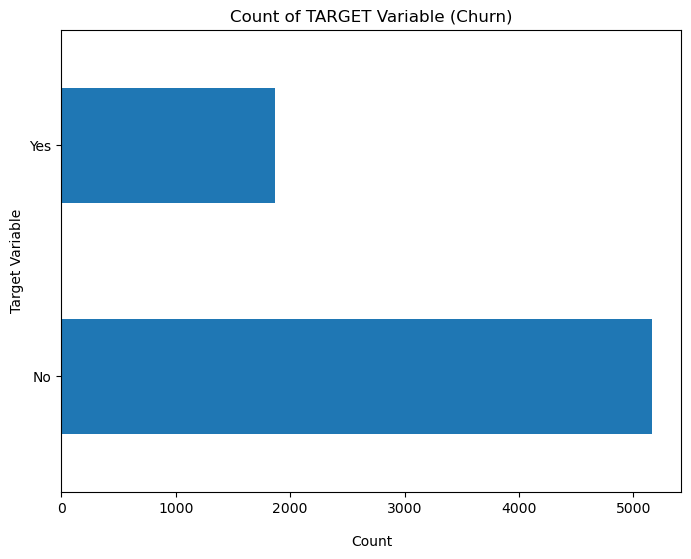

In [26]:
df['Churn'].value_counts().plot(kind='barh', figsize=(8, 6))
plt.xlabel("Count", labelpad=14)
plt.ylabel("Target Variable")
plt.title("Count of TARGET Variable (Churn)");
plt.show()

## Numerical Feature analysis

In [27]:
num_cols = df.select_dtypes('number').columns.to_list()
def numerical_dist_plot(data: pd.DataFrame):
    '''small functions to plot distribution plot for numerical cols'''
    
    df = data
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 6))
    axes = axes.flatten()
    
    for i, col in enumerate(num_cols[0:3]):   # limit to 3 plots
        sns.histplot(
            df[col],
            kde=True,
            ax=axes[i],
            color="#4C72B0",
            edgecolor="white"
        )
        
        axes[i].set_title(f"Distribution of {col}")
    
    plt.tight_layout()
    sns.despine()
    plt.show()

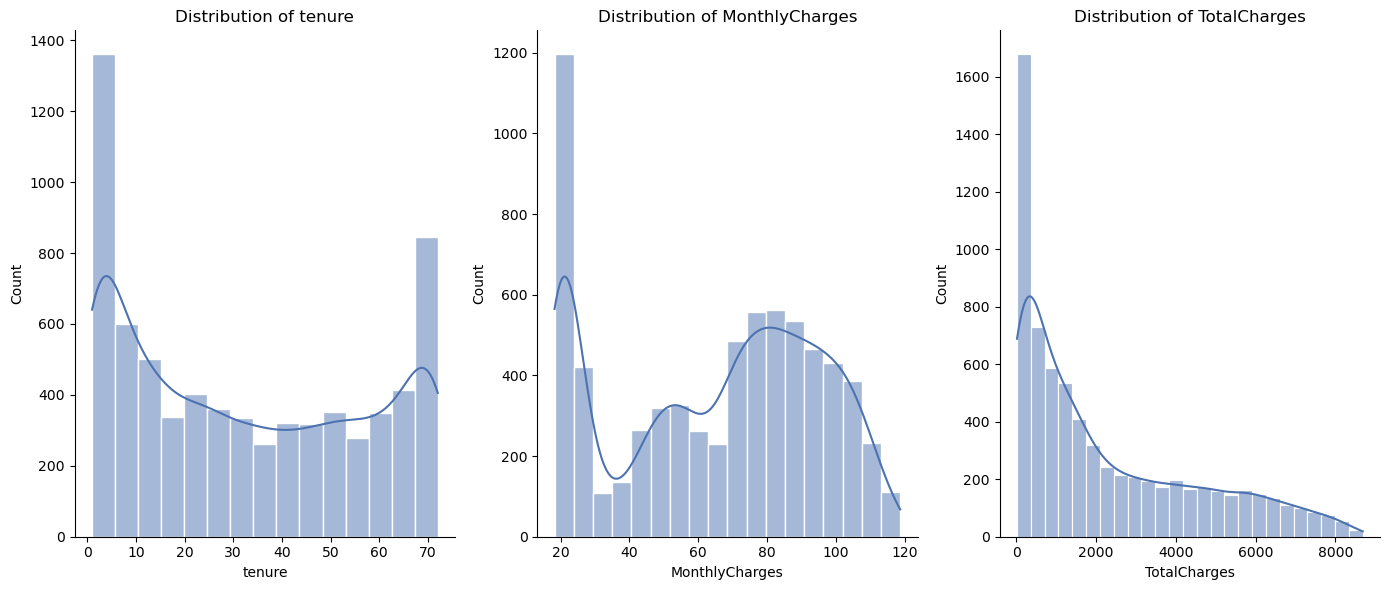

In [28]:
numerical_dist_plot(df)

In [29]:
from scipy.stats import skew, kurtosis, shapiro
from sklearn.feature_selection import mutual_info_classif

In [30]:
def skewness(df):
    df =  df
    for col in num_cols[0:]:
        print(f"{col} : {skew(df[col])}")
skewness(df)

tenure : 0.23768011839839964
MonthlyCharges : -0.22205554798978874
TotalCharges : 0.9614373590490068


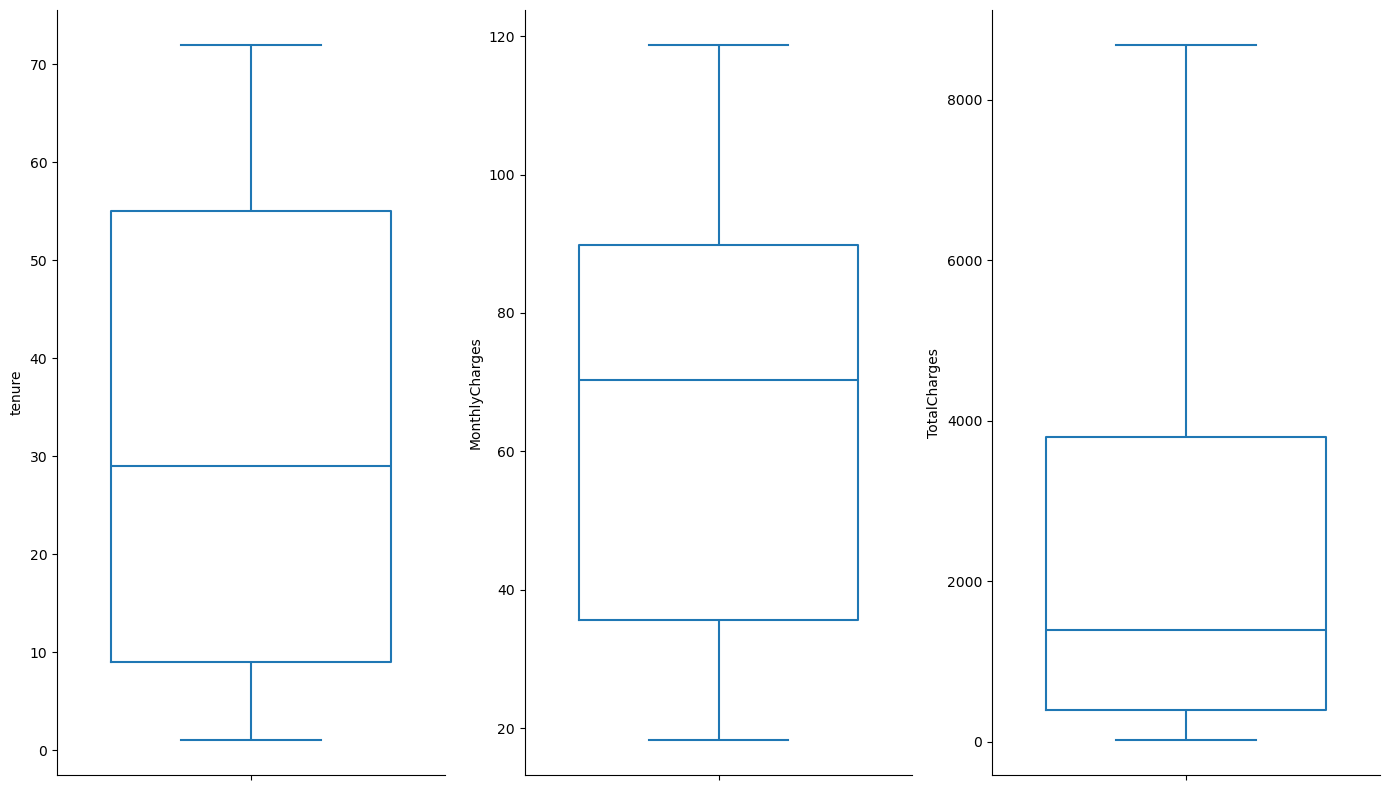

In [31]:
def box_plot(df):
    fig, axes, = plt.subplots(1, 3, figsize=(14, 8))
    axes = axes.flatten()
    for i, col in enumerate(num_cols[0:]):
        sns.boxplot(df[col], ax=axes[i], fill=False, gap=.1)
    plt.tight_layout()
    sns.despine()
    plt.show()
box_plot(df)

In [32]:
pearson = df[num_cols[0:]].corr().style.background_gradient('coolwarm')
pearson

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.246862,0.825880
MonthlyCharges,0.246862,1.000000,0.651065
TotalCharges,0.825880,0.651065,1.000000


In [33]:
spearman = df[num_cols[0:]].corr(method="spearman").style.background_gradient('coolwarm')

spearman

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.275339,0.889177
MonthlyCharges,0.275339,1.000000,0.638032
TotalCharges,0.889177,0.638032,1.000000


In [34]:
kendall = df[num_cols[0:]].corr(method="kendall").style.background_gradient('coolwarm')

kendall

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.189785,0.734016
MonthlyCharges,0.189785,1.000000,0.459904
TotalCharges,0.734016,0.459904,1.000000


In [35]:
from sklearn.feature_selection import mutual_info_classif

X = df[num_cols[0:]]
y = df['Churn']

mi = mutual_info_classif(X, y)

mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)
mi_scores

tenure            0.064705
MonthlyCharges    0.047315
TotalCharges      0.042418
dtype: float64

## Categorical Feature Analysis

In [41]:
cat_cols = df.select_dtypes(["object","category"]).columns.to_list()[:]
print(f"our categorical cols :\n {cat_cols}")

our categorical cols :
 ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn', 'tenure_group']


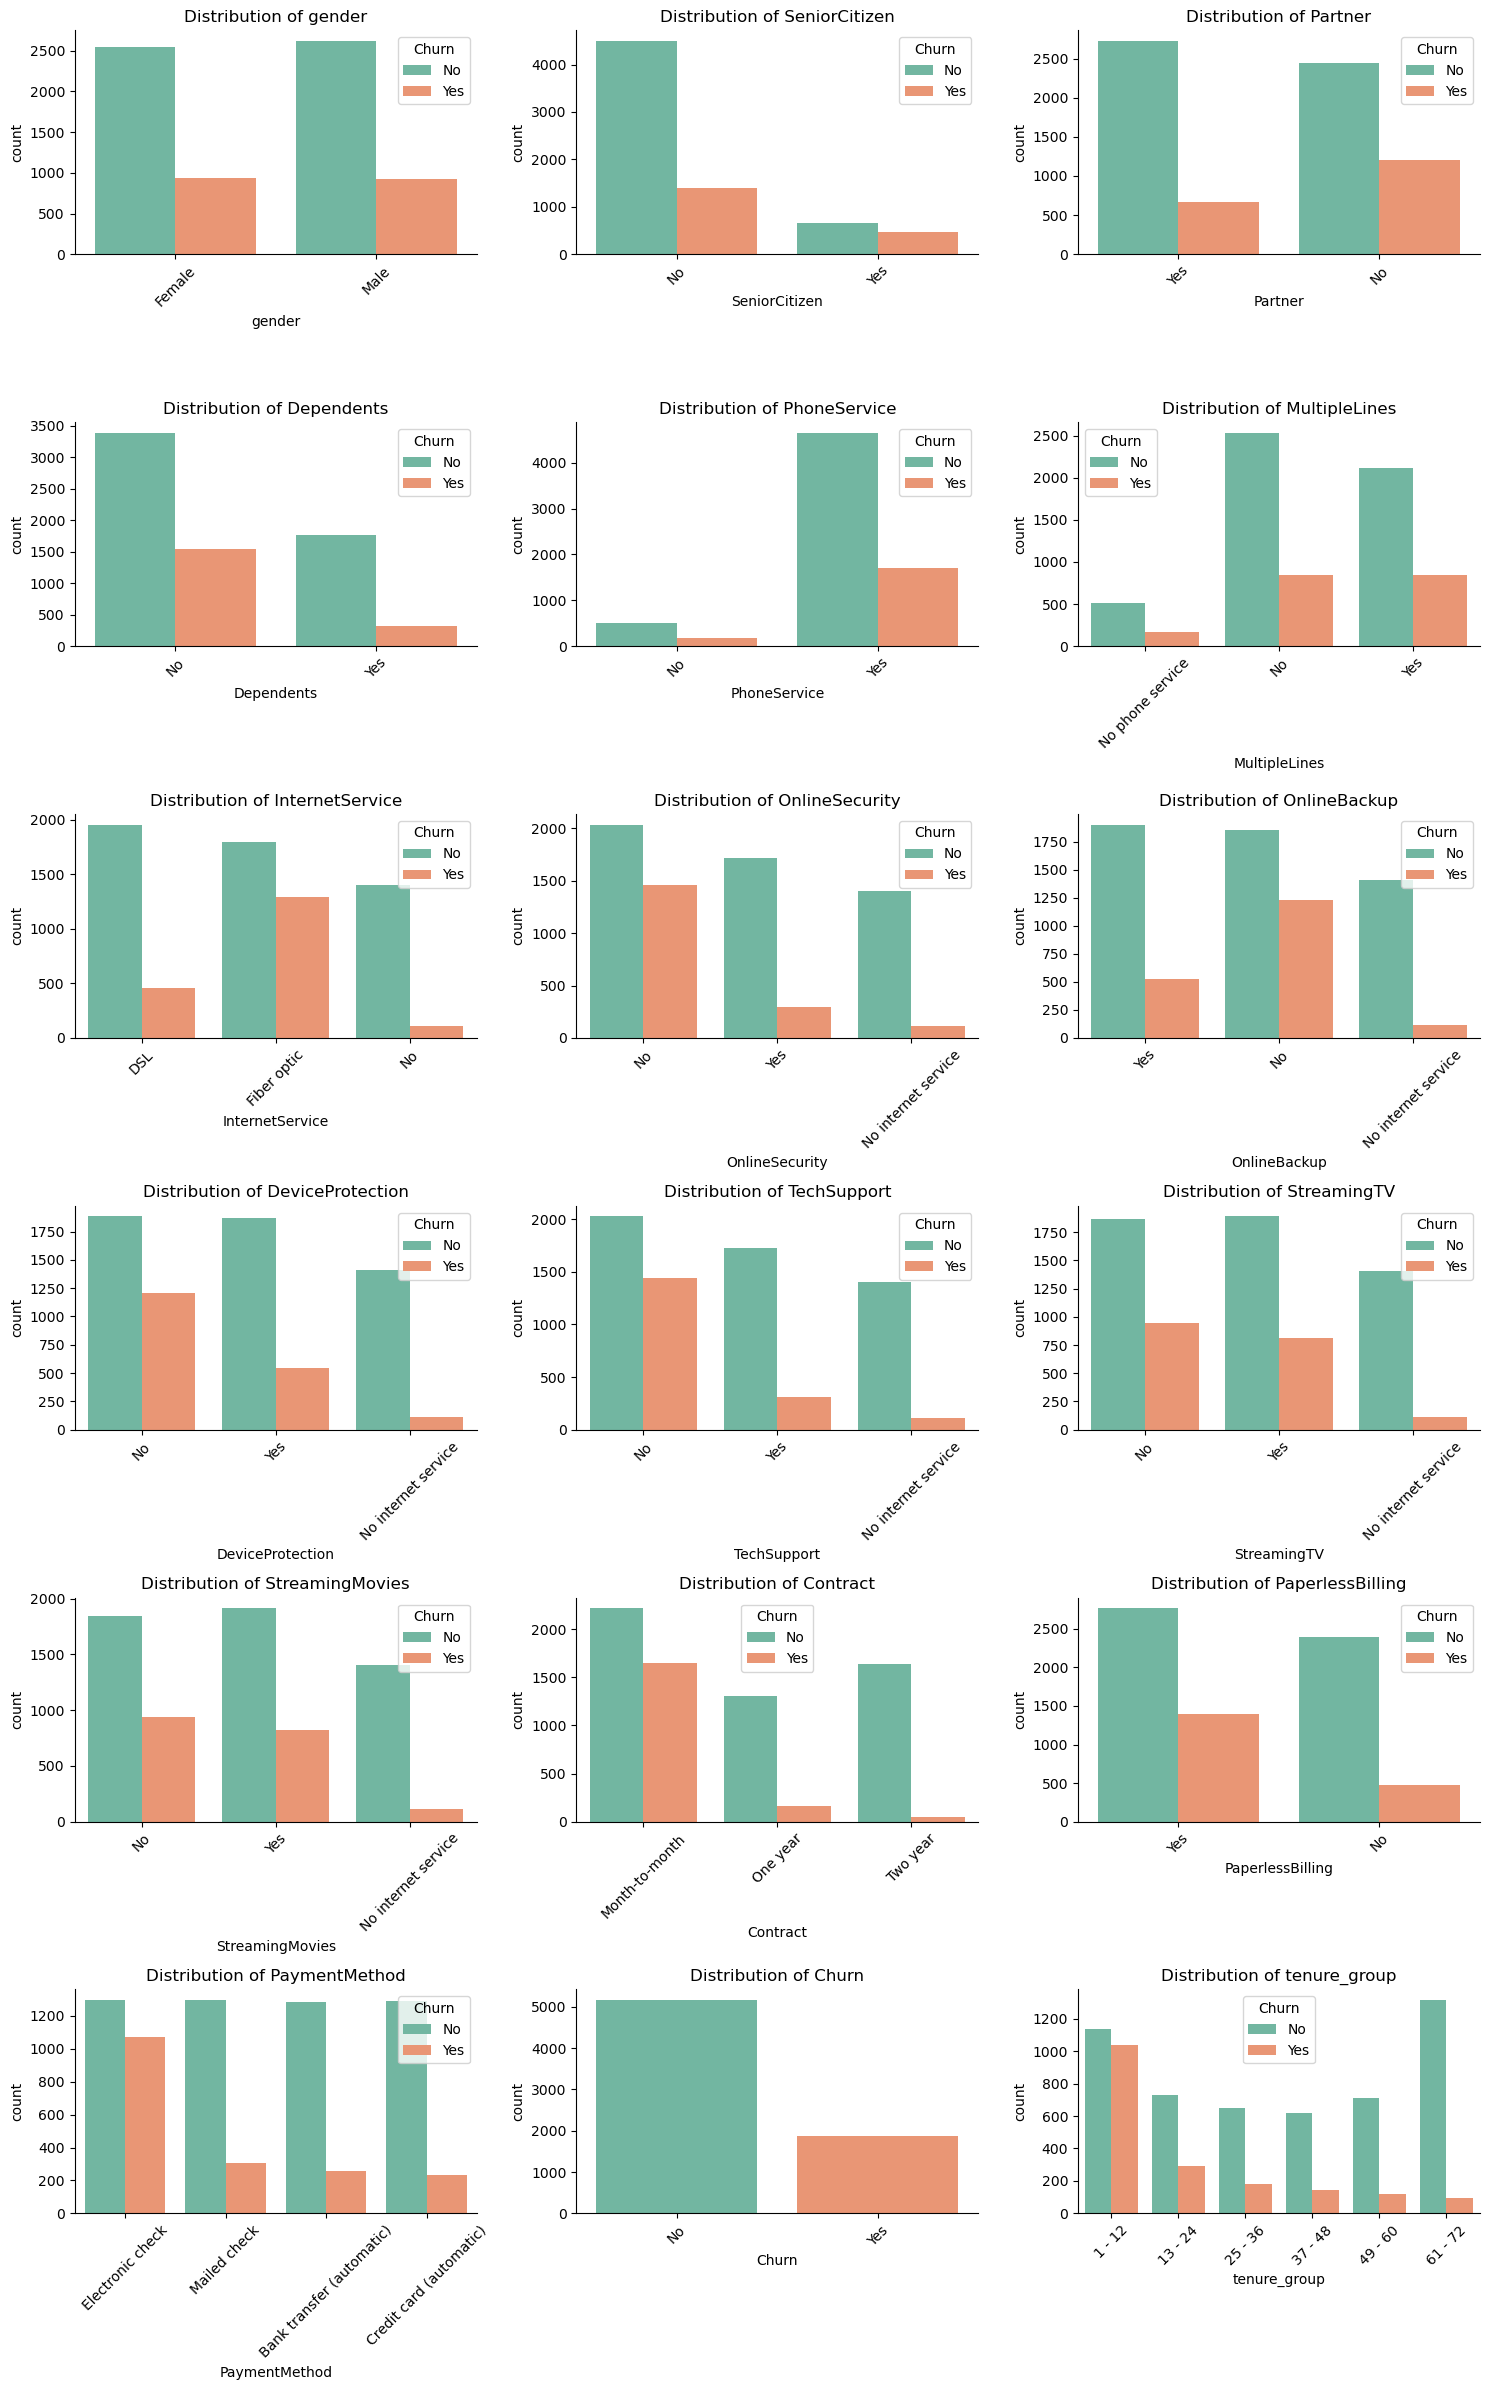

In [42]:
def count_plot(df):

    n_cols = 3
    n_rows = (len(cat_cols) + n_cols - 1) // n_cols  # Calculate the number of rows needed

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):

        sns.countplot(
            data=df,
            x=col,
            hue='Churn',
            palette="Set2",
            ax=axes[i]
        )

        axes[i].set_title(f"Distribution of {col}")
        axes[i].tick_params(axis='x', rotation=45)

    # remove empty plots
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    sns.despine()
    plt.show()
count_plot(df)

In [43]:
for col in cat_cols:

    display(
        pd.crosstab(
            df[col],
            df["Churn"],
            normalize="index"
        ).round(3)
    )

Churn,No,Yes
gender,,
Female,0.730,0.270
Male,0.738,0.262


Churn,No,Yes
SeniorCitizen,,
No,0.763,0.237
Yes,0.583,0.417


Churn,No,Yes
Partner,,
No,0.670,0.330
Yes,0.803,0.197


Churn,No,Yes
Dependents,,
No,0.687,0.313
Yes,0.845,0.155


Churn,No,Yes
PhoneService,,
No,0.750,0.250
Yes,0.733,0.267


...

Churn,No,Yes
Contract,,
Month-to-month,0.573,0.427
One year,0.887,0.113
Two year,0.972,0.028


Churn,No,Yes
PaperlessBilling,,
No,0.836,0.164
Yes,0.664,0.336


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),0.833,0.167
Credit card (automatic),0.847,0.153
Electronic check,0.547,0.453
Mailed check,0.808,0.192


Churn,No,Yes
Churn,,
No,1.0,0.0
Yes,0.0,1.0


Churn,No,Yes
tenure_group,,
1 - 12,0.523,0.477
13 - 24,0.713,0.287
25 - 36,0.784,0.216
37 - 48,0.810,0.190
49 - 60,0.856,0.144
61 - 72,0.934,0.066


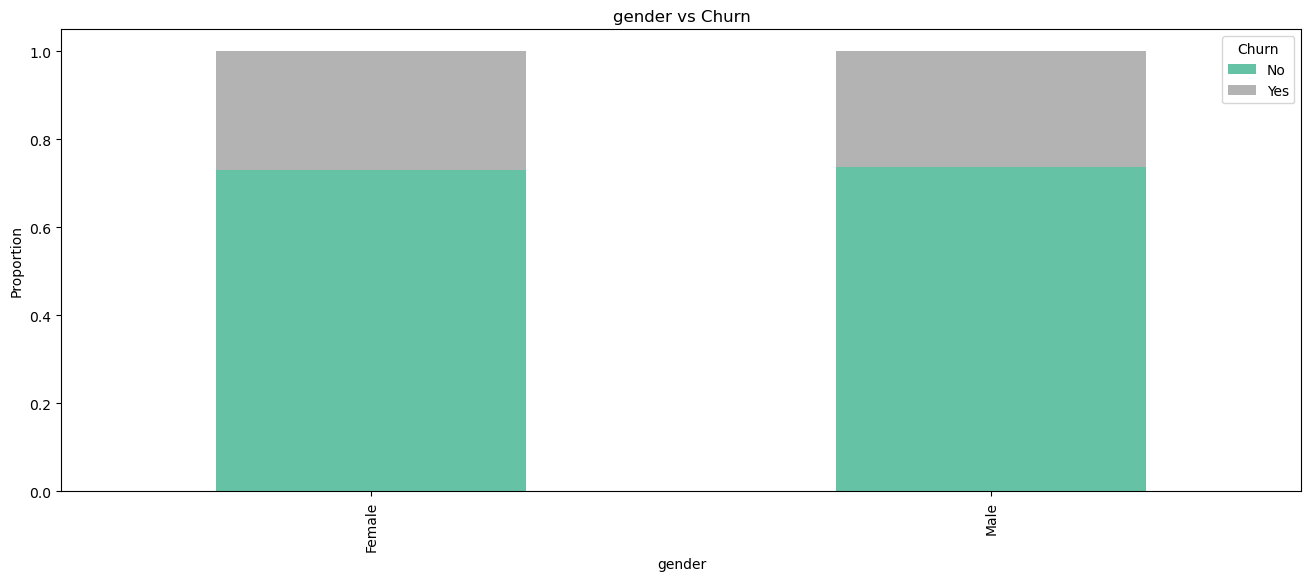

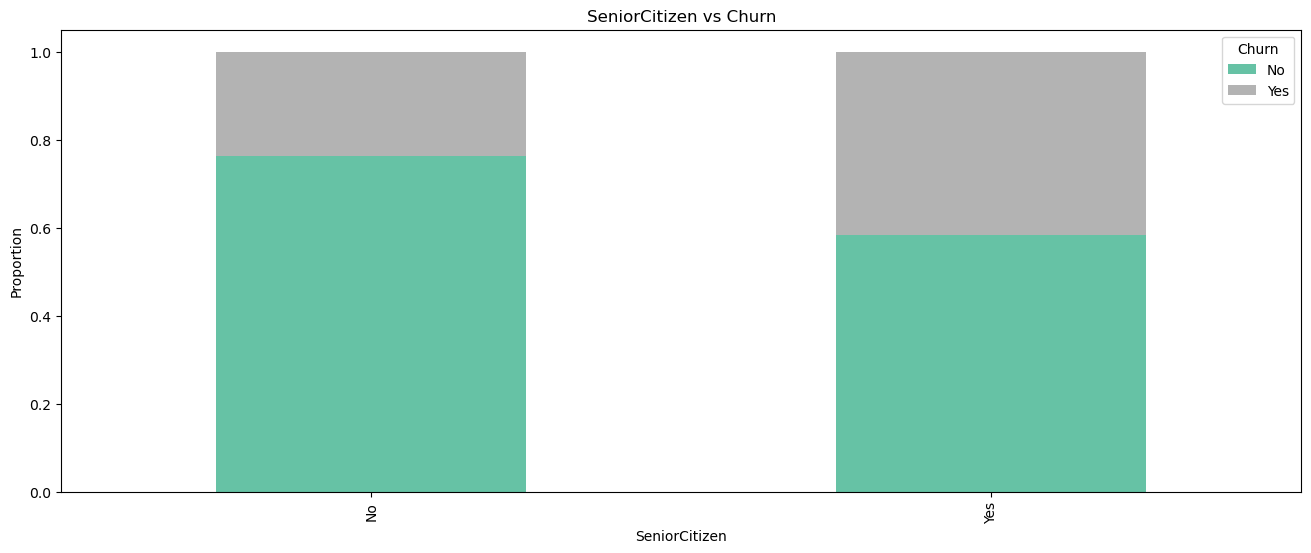

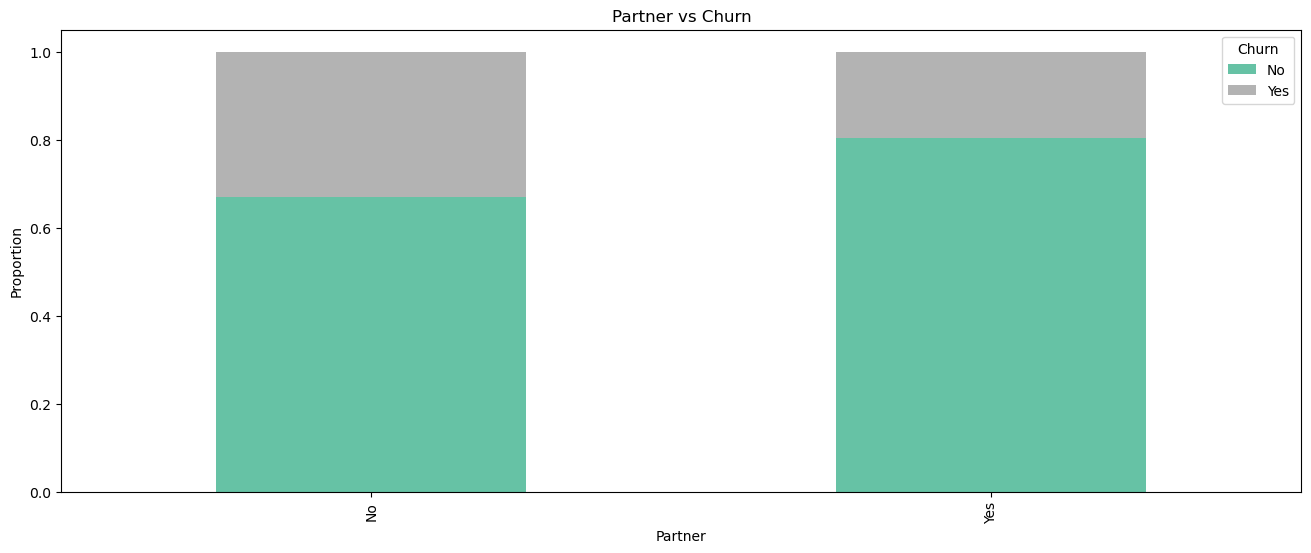

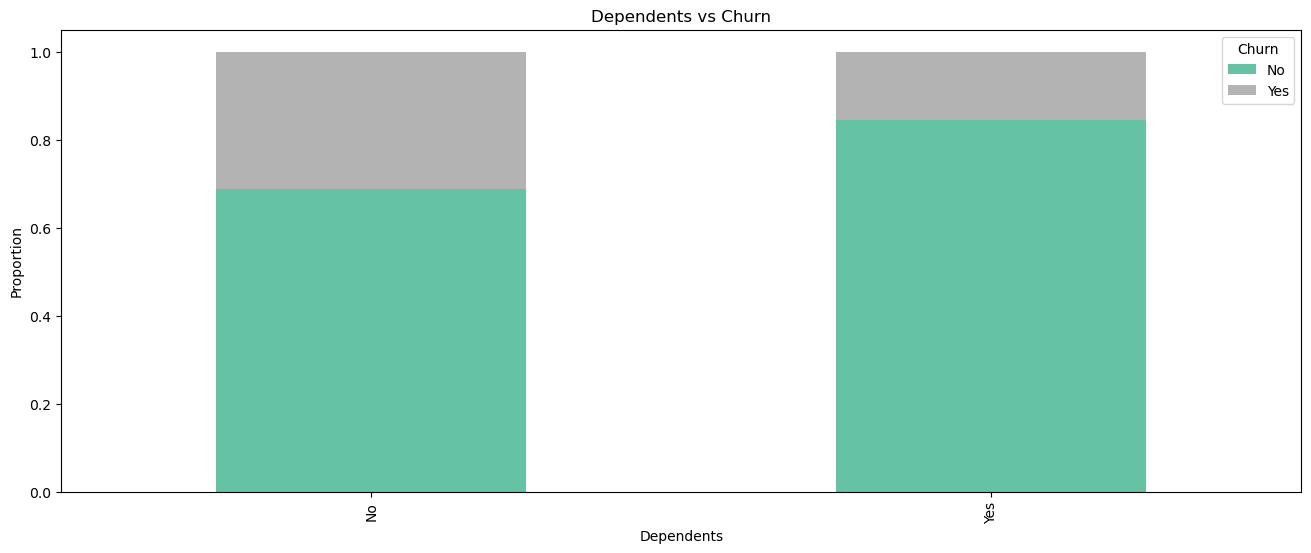

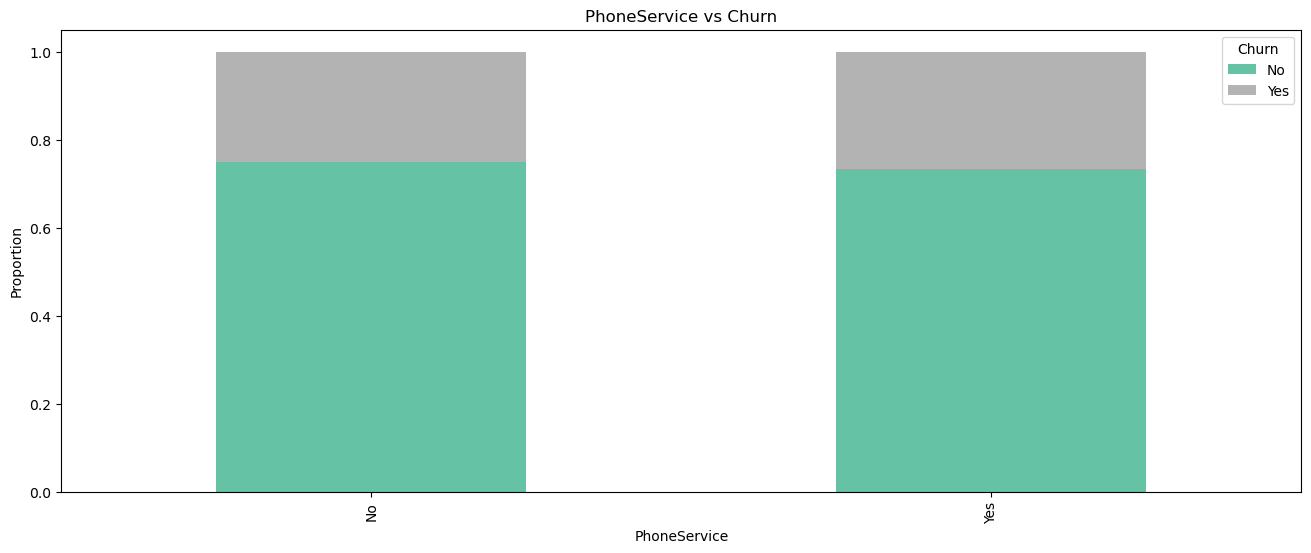

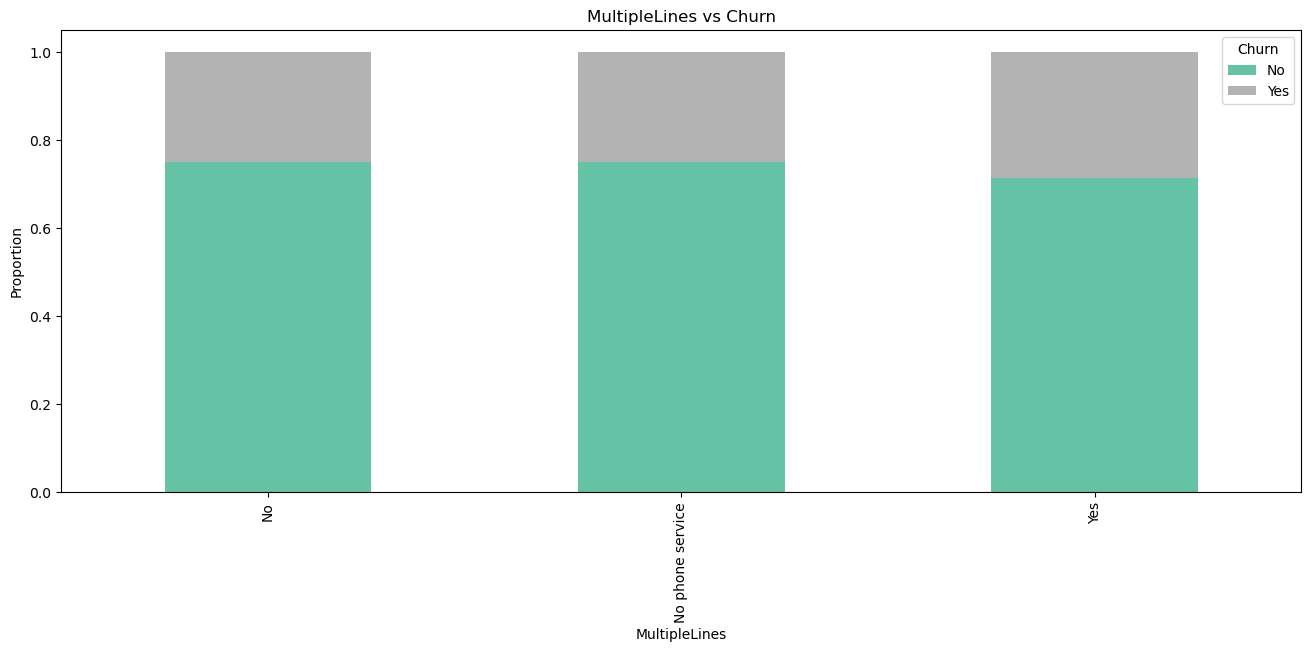

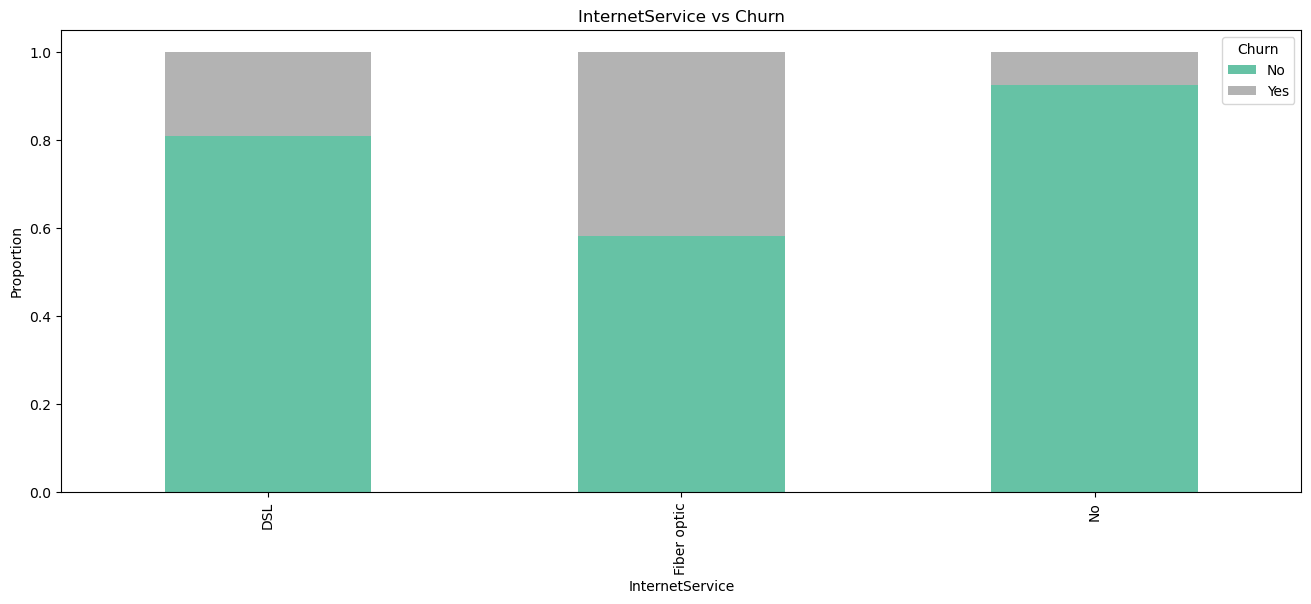

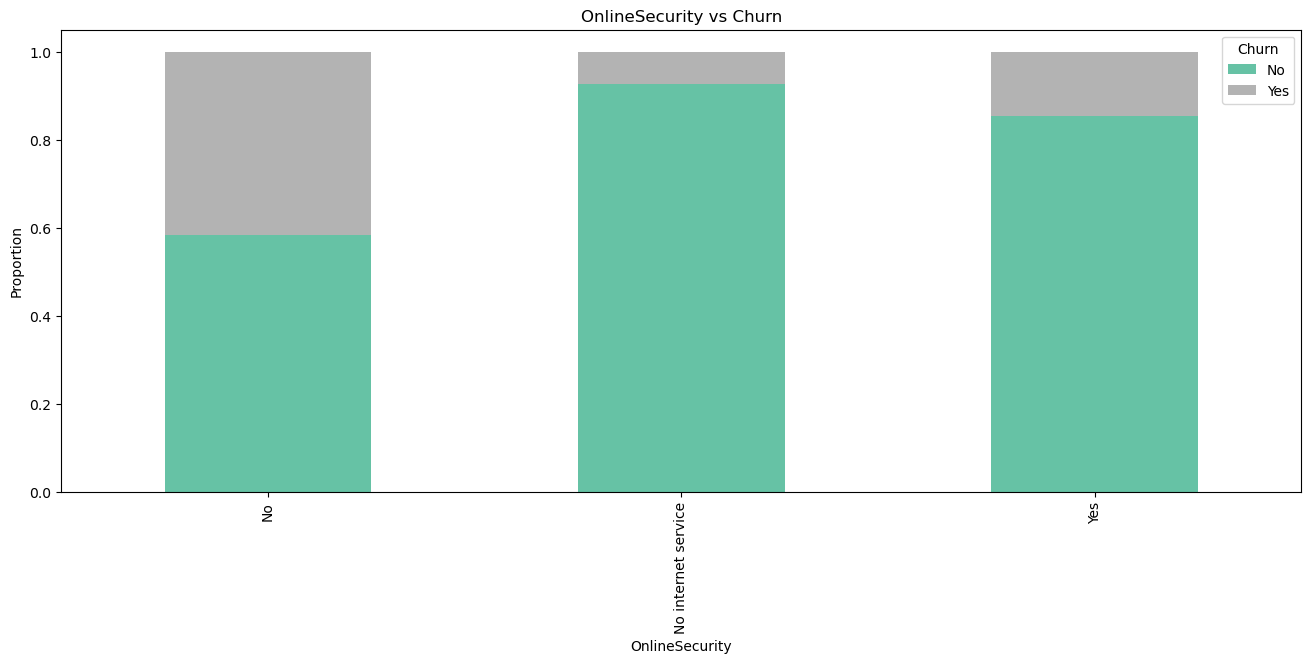

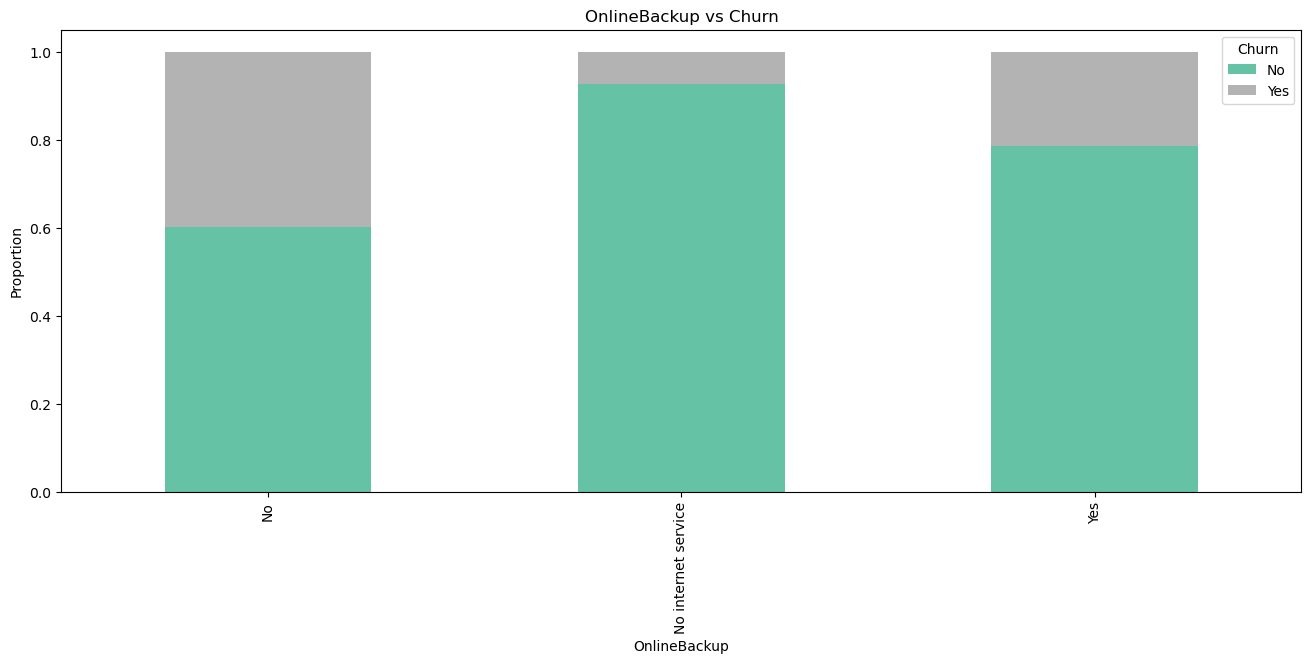

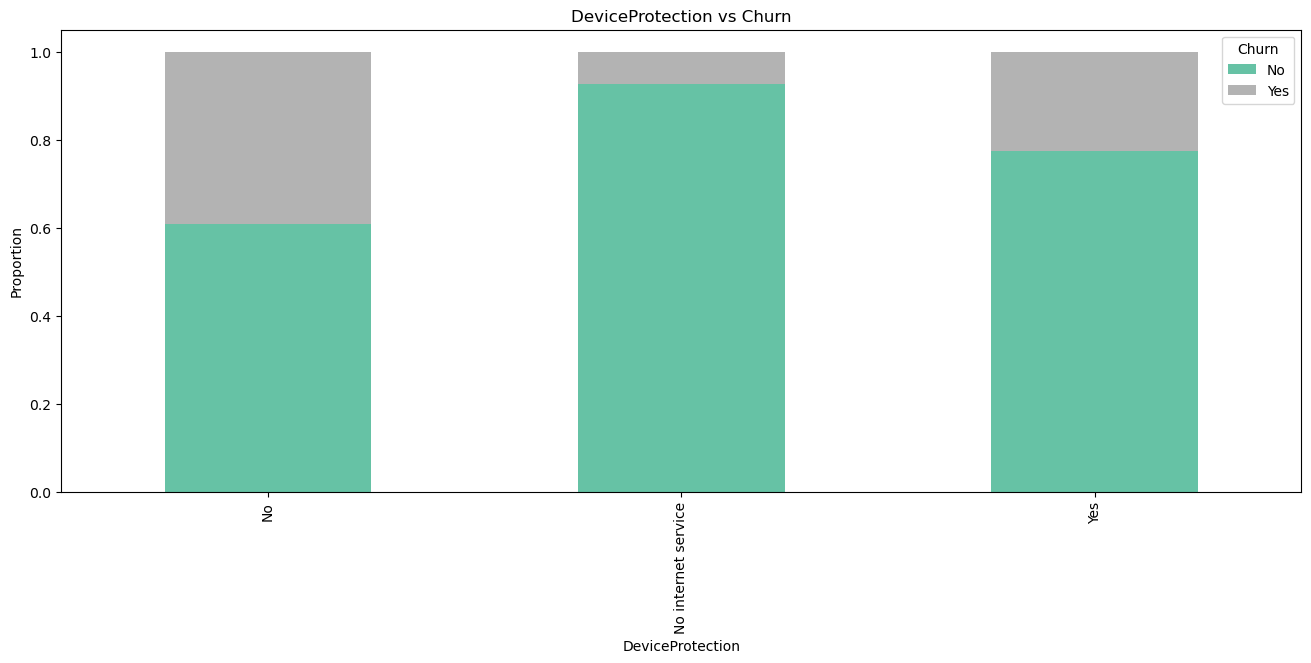

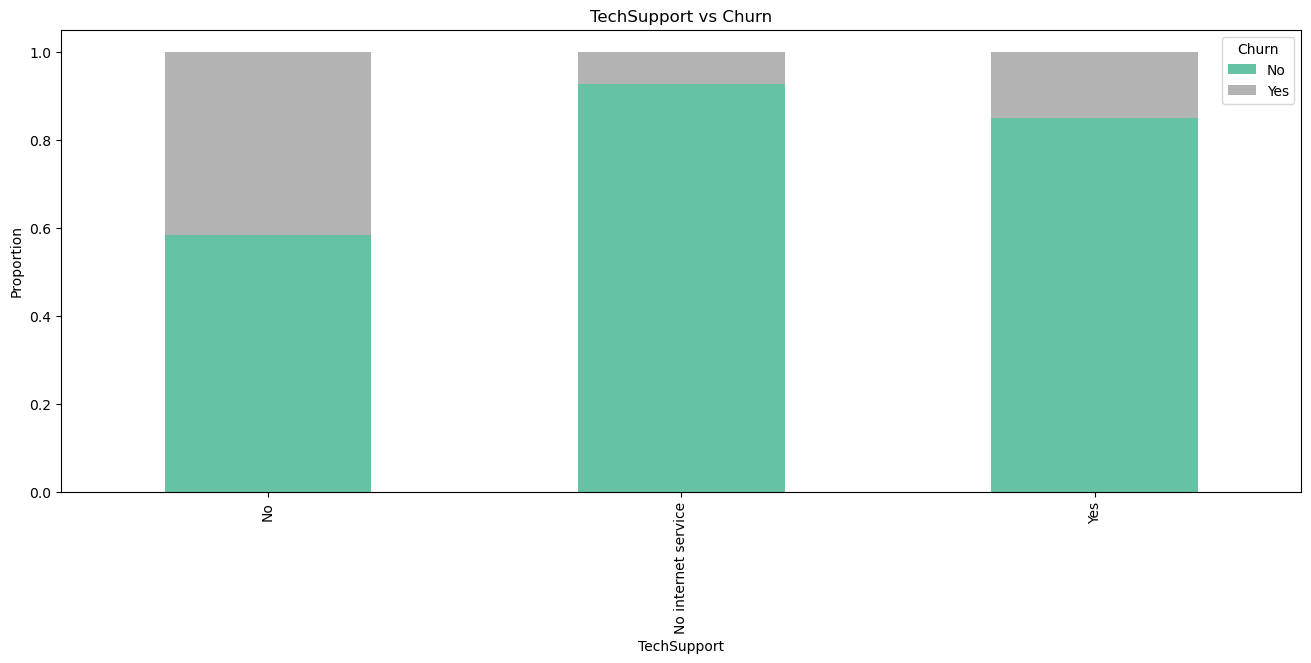

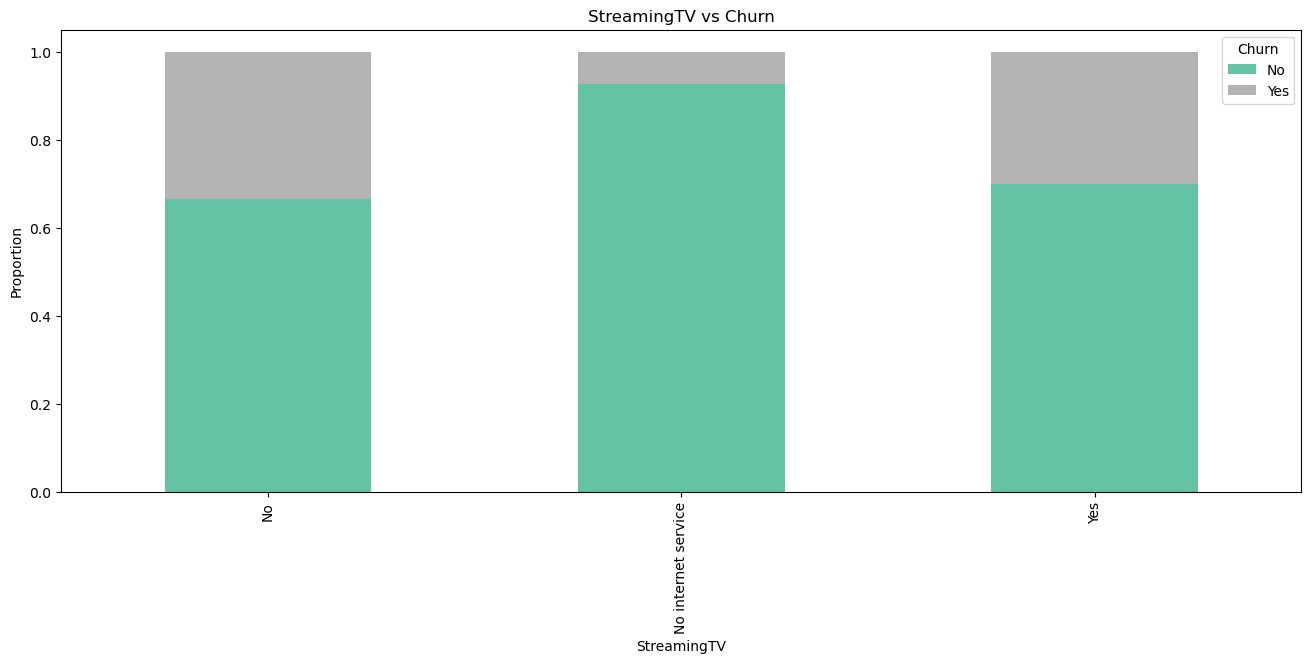

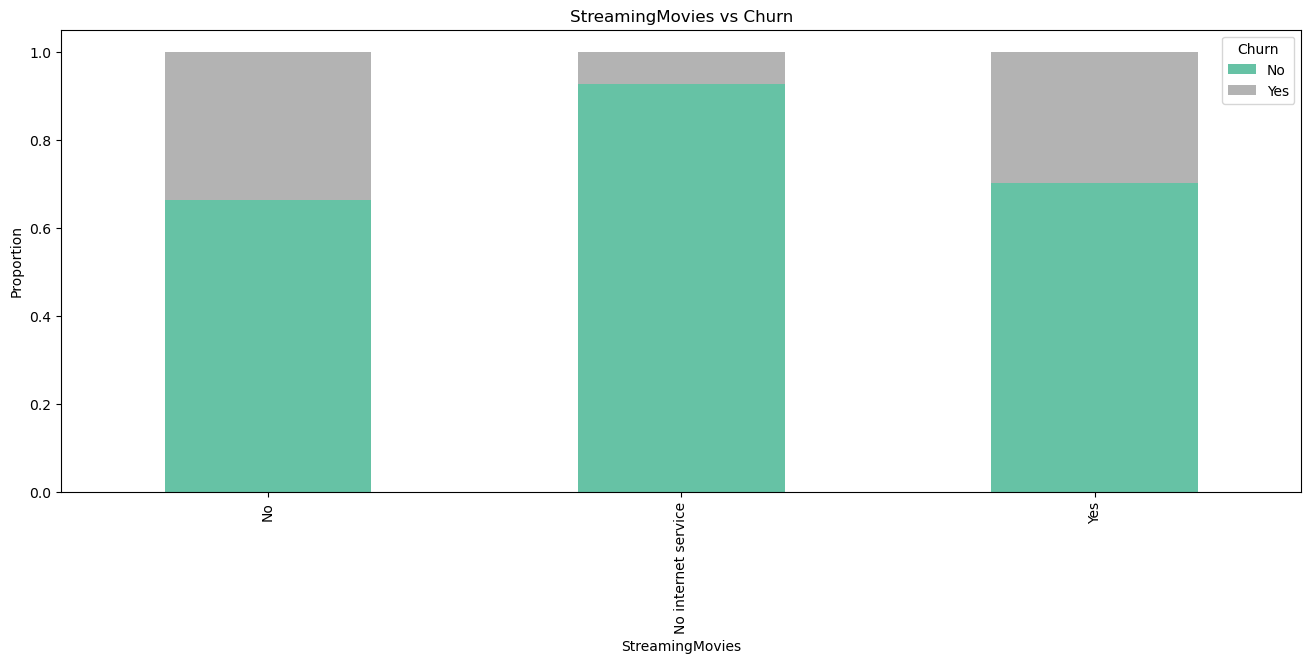

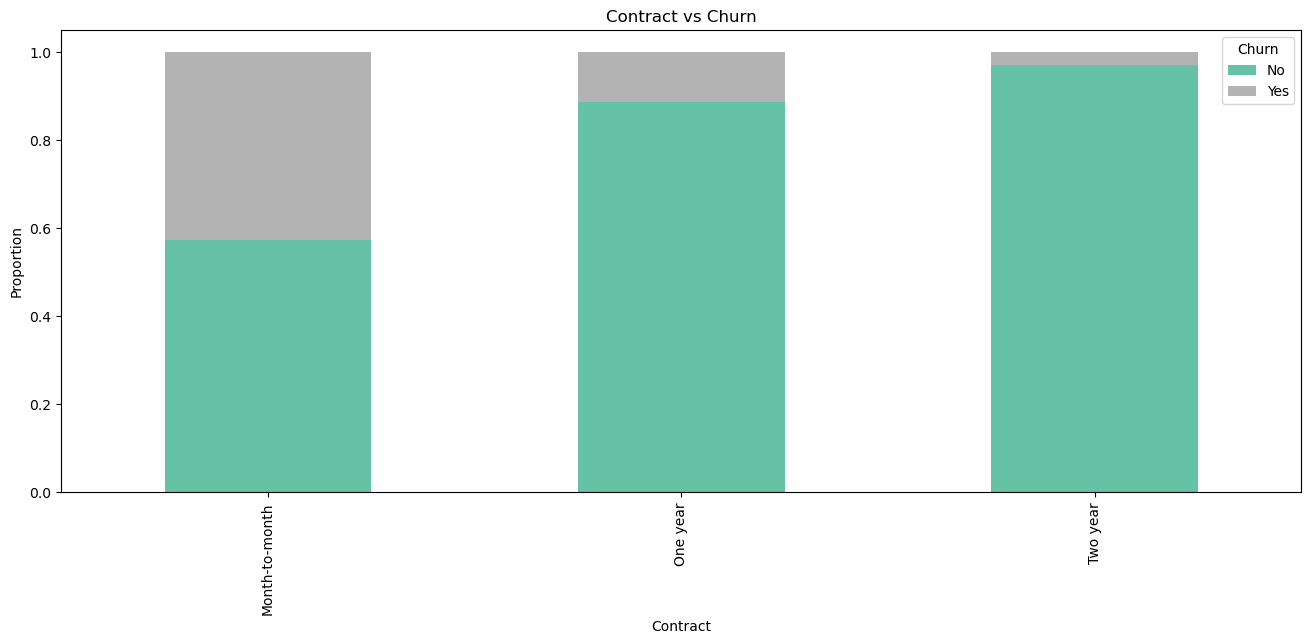

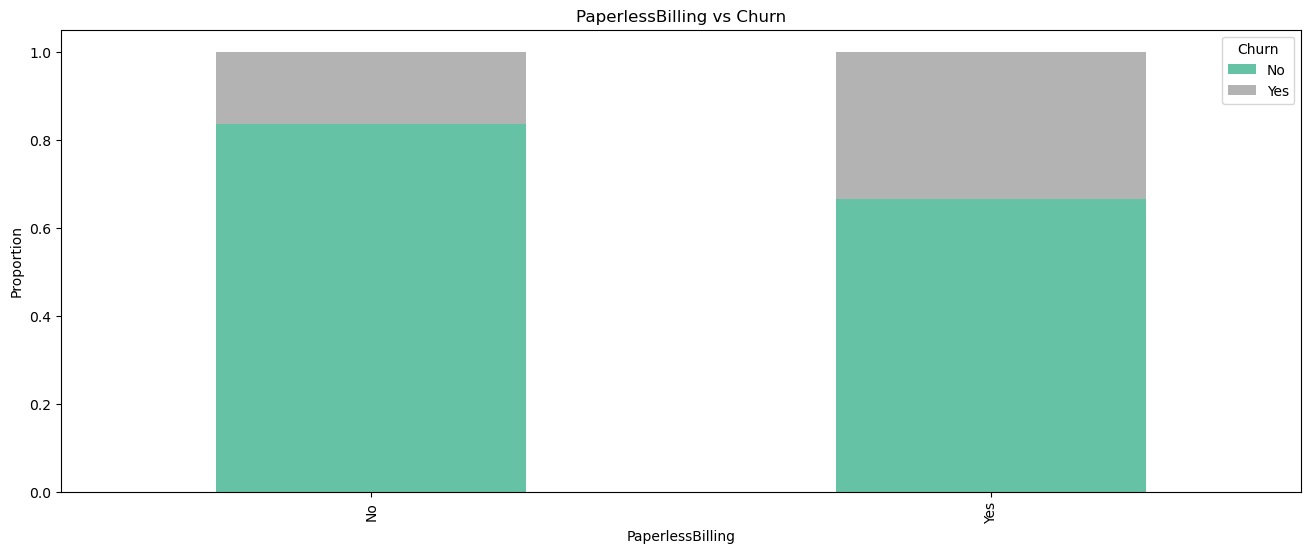

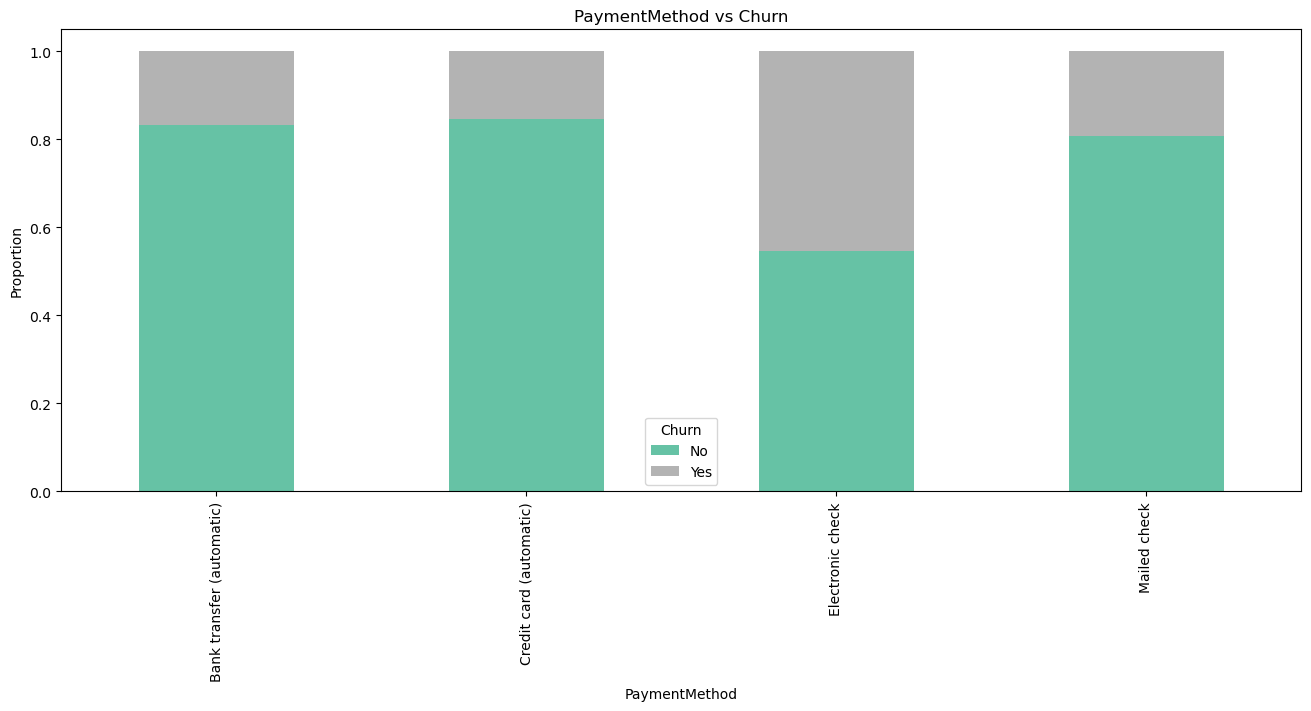

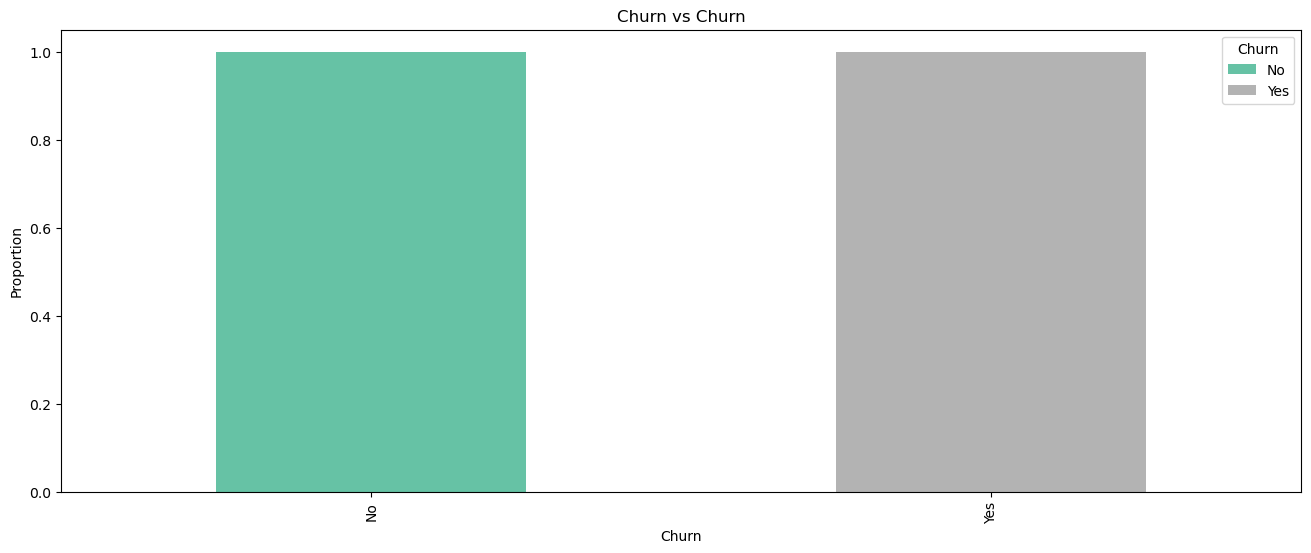

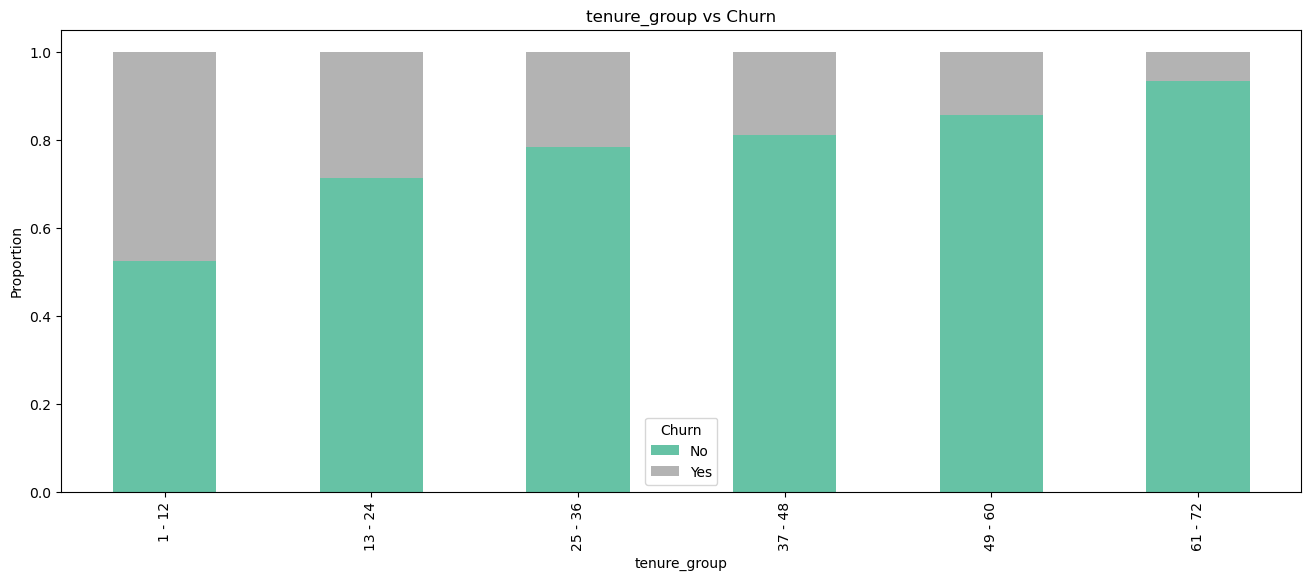

In [44]:
for col in cat_cols:

    ct = pd.crosstab(df[col], df["Churn"], normalize="index")

    ct.plot(
        kind="bar",
        stacked=True,
        figsize=(16,6),
        colormap="Set2"
    )

    plt.title(f"{col} vs Churn")
    plt.ylabel("Proportion")
    plt.show()

## Outlier detection

In [50]:
def detect_outliers(df, col):

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return df[
    ((df[col] < lower) |
     (df[col] > upper)).any(axis=1)]


In [54]:
detect_outliers(df, num_cols)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group


In [55]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = (
    ((df[num_cols] < lower) |
     (df[num_cols] > upper))
    .sum()
)

print(outlier_count)

tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


## Category vs Numeric Distribution

C:\Users\ASUS\AppData\Local\Temp\ipykernel_24440\2264070934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24440\2264070934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24440\2264070934.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


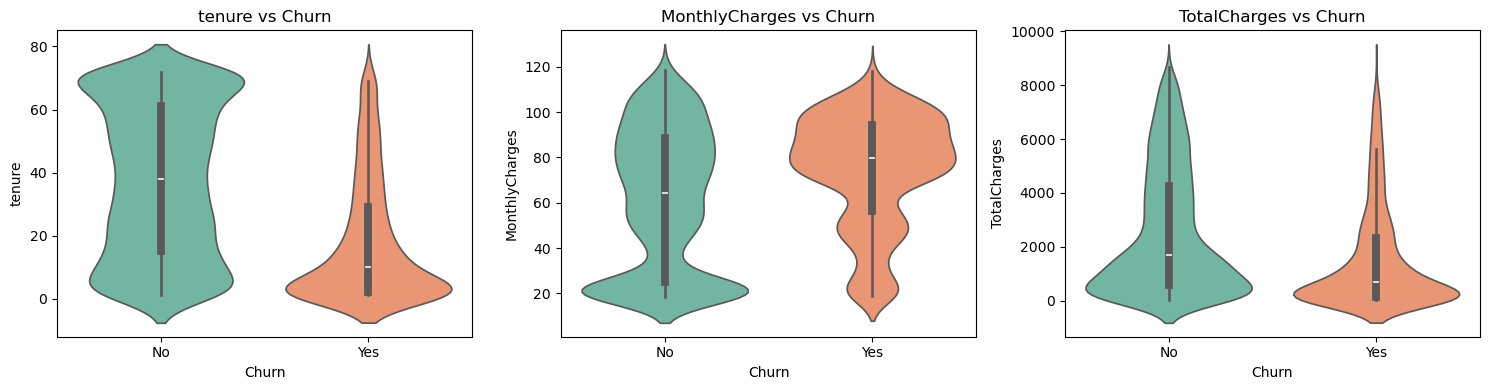

In [58]:
def violin_numeric_vs_target(df, num_cols, target):

    n_cols = 3
    n_rows = (len(num_cols) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols,4*n_rows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):

        sns.violinplot(
            data=df,
            x=target,
            y=col,
            palette="Set2",
            ax=axes[i]
        )

        axes[i].set_title(f"{col} vs {target}")

    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
violin_numeric_vs_target(df, num_cols, "Churn")

## Save the clean data

#### To CSV File

In [59]:
df.to_csv(r"C:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\Dataset\churn_data.csv", index=False)

#### To pgsql

In [61]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

connection_url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password="Kartik@2815",
    host="localhost",
    port=5432,
    database="customer_churn"
)

engine = create_engine(connection_url)

df.to_sql(
    "churn_data",
    engine,
    if_exists="replace",
    index=False
)

print("Data successfully loaded!")

Data successfully loaded!
